# bicm before and after version 4.0 on the Web of Life networks

This notebook downloads **all the networks** of the [Web of Life](https://www.web-of-life.es/) database (ecological interaction networks: pollination, seed dispersal, host-parasite, food webs and others) and runs on each of them the BiCM solver and the validated projections on both layers, with two versions of `bicm`:

* **before**: version 3.5.0, the last one before the integration of the fast projection and of the weighted models;
* **after**: the version installed in this environment (4.0.0 or later).

It then compares the two versions on:

1. the solution of the BiCM;
2. the running time of the projections;
3. the p-values, also against an independent reference computed by brute force;
4. the validated links;
5. the weighted models BiWCM_d (integer weights) and BiWCM_c (continuous weights) on the weighted networks of the database.

Each version runs in its own process (`wol_worker.py`), since two versions of a package cannot be imported together. Downloads and results are cached in `data/` and `results/`: set `FORCE = True` to repeat everything.

Requirements: `pip install bicm pandas matplotlib tqdm` (tqdm is needed only by the old version), and git or an internet connection to get the old version.

In [1]:
import csv
import io
import pickle
import subprocess
import sys
import tarfile
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numba import njit, prange

import bicm
from bicm import BipartiteGraph
from bicm.pvalues import poibin_tail

import wol_worker

HERE = Path.cwd()
DATA, RESULTS, OLD = HERE / 'data', HERE / 'results', HERE / 'bicm_old'
OLD_VERSION, OLD_COMMIT = '3.5.0', 'a35e013'

ALPHA = 0.05             # significance level of the projections (FDR)
TIMEOUT = 120            # seconds allowed to one projection
MAX_POIBIN_COST = 3e9    # the old exact method is skipped above this estimated cost (about 40 s)
FORCE = False            # True: download and compute everything again

DATA.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
print('bicm after :', bicm.__version__)

# Chart style: one colour for each version, used in every chart
BEFORE, AFTER, INK, MUTED = '#eb6834', '#2a78d6', '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#c3c2b7',
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'font.size': 9.5,
    'legend.frameon': False,
})

bicm after : 4.0.0


## 1. Download the networks

The Web of Life API returns all the networks in one request, as a list of interactions `(network_name, species1, species2, connection_strength)`, and a table with the description of every network. The weights are ignored: a link exists where the connection strength is positive. `species1` are the rows of the biadjacency matrix and `species2` the columns.

In [2]:
API = 'https://www.web-of-life.es/'


def download(url, path):
    if path.exists() and not FORCE:
        return
    request = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(request, timeout=600) as response:
        path.write_bytes(response.read())


download(API + 'get_networks.php', DATA / 'networks.json')
download(API + 'get_network_info.php', DATA / 'network_info.csv')

networks = wol_worker.load_networks(DATA / 'networks.json')
info = pd.read_csv(DATA / 'network_info.csv').set_index('network_name')


def degenerate_nodes(matrix):
    # Rows and columns linked to the whole opposite layer: their links are certain in the BiCM
    return int((matrix.sum(1) == matrix.shape[1]).sum() + (matrix.sum(0) == matrix.shape[0]).sum())


nets = pd.DataFrame({
    'type': [info['network_type'].get(name, 'unknown') for name in networks],
    'rows': [m.shape[0] for m, _, _ in networks.values()],
    'columns': [m.shape[1] for m, _, _ in networks.values()],
    'links': [int(m.sum()) for m, _, _ in networks.values()],
    'full_nodes': [degenerate_nodes(m) for m, _, _ in networks.values()],
}, index=list(networks))
print(len(nets), 'networks with at least one link,', len(info), 'listed in the database')
summary = nets.groupby('type').agg(networks=('rows', 'size'), median_rows=('rows', 'median'),
                                   median_columns=('columns', 'median'), max_rows=('rows', 'max'),
                                   max_columns=('columns', 'max'), with_full_nodes=('full_nodes', lambda s: (s > 0).sum()))
summary

318 networks with at least one link, 330 listed in the database


,networks,median_rows,median_columns,max_rows,max_columns,with_full_nodes
type,,,,,,
Anemone-Fish,17,4.0,4.0,10,26,3
Food Webs,33,40.0,42.0,248,244,0
Host-Parasite,51,11.0,19.0,27,40,6
Plant-Ant,5,11.0,16.0,48,41,0
Plant-Herbivore,4,29.0,44.0,54,88,1
Pollination,174,17.0,26.0,456,1044,14
Seed Dispersal,34,19.5,15.5,207,110,12


## 2. Get the old version and run both

The old version is taken from the git history of the repository if the notebook is inside it, otherwise from PyPI. It is unpacked in `bicm_old/` and never installed.

The worker runs, for every network: the solver, and then the projection on the rows and on the columns with the four methods (`poisson`, `poibin`, `normal`, `rna`) and the FDR validation. It uses the default number of processes or threads of each version. The exact method of the old version (`poibin`) is skipped on the layers where it would take more than about 40 seconds.

In [3]:
if not (OLD / 'bicm' / '__init__.py').exists() or FORCE:
    OLD.mkdir(exist_ok=True)
    repo = subprocess.run(['git', 'rev-parse', '--show-toplevel'], capture_output=True, text=True, cwd=HERE)
    archive = None
    if repo.returncode == 0:
        archive = subprocess.run(['git', 'archive', OLD_COMMIT, 'bicm'], capture_output=True, cwd=repo.stdout.strip())
    if archive is not None and archive.returncode == 0:
        tarfile.open(fileobj=io.BytesIO(archive.stdout)).extractall(OLD)
    else:
        subprocess.run([sys.executable, '-m', 'pip', 'download', '-q', '--no-deps', '-d', str(OLD / 'wheel'),
                        'bicm==' + OLD_VERSION], check=True)
        zipfile.ZipFile(next((OLD / 'wheel').glob('*.whl'))).extractall(OLD)


def run_worker(tag, *extra):
    output = RESULTS / (tag + '.pkl')
    if not output.exists() or FORCE:
        command = [sys.executable, '-W', 'ignore', '-u', 'wol_worker.py', '--networks', str(DATA / 'networks.json'),
                   '--output', str(output), '--alpha', str(ALPHA), *extra]
        process = subprocess.Popen(command, cwd=HERE, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)
        for line in process.stdout:
            print(tag, '|', line.rstrip())
        if process.wait() != 0:
            raise RuntimeError(process.stderr.read()[-3000:])
    with open(output, 'rb') as handle:
        return pickle.load(handle)


new = run_worker('new')
old = run_worker('old', '--bicm-path', str(OLD), '--timeout', str(TIMEOUT), '--max-poibin-cost', str(MAX_POIBIN_COST))
print('before:', old.pop('__version__'), '  after:', new.pop('__version__'))

before: 3.5.0   after: 4.0.0


### What ran

One row for each method: on how many layers (two for each network) each version produced a result. Everything that failed or was skipped is listed, nothing is dropped silently.

In [4]:
METHODS = wol_worker.METHODS
LAYERS = ('rows', 'columns')


def status(result):
    if result is None:
        return 'solver failed'
    if 'error' in result:
        return 'error'
    return result.get('skipped', 'ok')


records = []
for name in nets.index:
    for layer in LAYERS:
        for method in METHODS:
            before = old[name]['projections'].get((layer, method)) if 'error' not in old[name] else None
            after = new[name]['projections'].get((layer, method)) if 'error' not in new[name] else None
            records.append({'network': name, 'layer': layer, 'method': method,
                            'status_before': status(before), 'status_after': status(after),
                            'time_before': (before or {}).get('time', np.nan),
                            'time_after': (after or {}).get('time', np.nan),
                            'pairs': len(after['pvals']) if after and 'pvals' in after else 0})
runs = pd.DataFrame(records)
coverage = pd.concat({'before': runs.groupby('method')['status_before'].value_counts().unstack(fill_value=0),
                      'after': runs.groupby('method')['status_after'].value_counts().unstack(fill_value=0)}, axis=1)
display(coverage.loc[list(METHODS)])
for version, data in (('before', old), ('after', new)):
    errors = {(name, key): res['error'] for name in nets.index for key, res in data[name]['projections'].items()
              if 'error' in res}
    errors.update({(name, 'solver'): data[name]['error'] for name in nets.index if 'error' in data[name]})
    print(version, ':', len(errors), 'errors', pd.Series(errors).value_counts().to_dict() if errors else '')

before      after
         error   ok    ok
method                   
poisson      8  628   636
poibin       8  628   636
normal       8  628   636
rna          8  628   636

before : 32 errors {'TypeError("\'NoneType\' object is not subscriptable")': 32}
after : 0 errors 


## 3. The solver

The solver was not changed: the fitnesses must be the same. In a perfectly nested network every link is certain and there is nothing to solve: the old version leaves the fitnesses undefined and its projections fail, the new one returns the probability matrix and p-values equal to one.

In [5]:
def relative_difference(a, b):
    # Largest |a - b| / max(|a|, |b|), with 0 for the entries that are equal (also both infinite or null)
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    if len(a) == 0:
        return 0.0
    with np.errstate(invalid='ignore', divide='ignore'):
        diff = np.abs(a - b) / np.maximum(np.abs(a), np.abs(b))
    diff[a == b] = 0.0
    return float(np.nanmax(diff))


def has_solution(record):
    return np.ndim(record.get('x')) == 1


solved = [name for name in nets.index if has_solution(old[name]) and has_solution(new[name])]
unsolved = [name for name in nets.index if name not in solved]
print('not solved by the old version:', {name: '{} x {}'.format(*old[name]['shape']) for name in unsolved
                                         if not has_solution(old[name])})
print('not solved by the new version:', [name for name in unsolved if not has_solution(new[name])])
nets['fitness_diff'] = pd.Series({name: max(relative_difference(old[name]['x'], new[name]['x']),
                                            relative_difference(old[name]['y'], new[name]['y'])) for name in solved})
print(len(solved), 'networks solved by both versions')
print('largest relative difference of the fitnesses: {:.1e}'.format(nets['fitness_diff'].max()))
print('solver time, all networks: before {:.1f} s, after {:.1f} s'.format(
    sum(old[n]['solve_time'] for n in solved), sum(new[n]['solve_time'] for n in solved)))

not solved by the old version: {'M_AF_002_03': '3 x 2', 'M_SD_026': '3 x 3', 'M_SD_029': '4 x 5', 'A_HP_015': '3 x 7'}
not solved by the new version: []
314 networks solved by both versions
largest relative difference of the fitnesses: 0.0e+00
solver time, all networks: before 0.6 s, after 0.4 s


## 4. Speed of the projections

Total time of each method over the layers where both versions ran, and distribution of the speed-up (time before / time after). The compilation of the jitted functions is excluded for both versions.

In [6]:
both = runs[(runs.status_before == 'ok') & (runs.status_after == 'ok')].copy()
both['speedup'] = both.time_before / both.time_after
speed = both.groupby('method').agg(layers=('speedup', 'size'), total_before_s=('time_before', 'sum'),
                                   total_after_s=('time_after', 'sum'), median_speedup=('speedup', 'median'),
                                   min_speedup=('speedup', 'min'), max_speedup=('speedup', 'max')).loc[list(METHODS)]
speed['total_speedup'] = speed.total_before_s / speed.total_after_s
skipped = runs[(runs.method == 'poibin') & (runs.status_before != 'ok') & (runs.status_after == 'ok')]
print('exact method on the {} layers that the old version skipped, did not finish or failed on: {:.2f} s in total after'.format(
    len(skipped), skipped.time_after.sum()))
speed.round(3)

exact method on the 8 layers that the old version skipped, did not finish or failed on: 0.01 s in total after


,layers,total_before_s,total_after_s,median_speedup,min_speedup,max_speedup,total_speedup
method,,,,,,,
poisson,628,37.325,0.592,55.051,12.040,217.165,63.039
poibin,628,124.691,1.122,78.686,5.065,5080.564,111.130
normal,628,51.004,0.537,66.518,7.064,304.813,94.922
rna,628,61.592,0.599,62.522,4.325,288.090,102.832


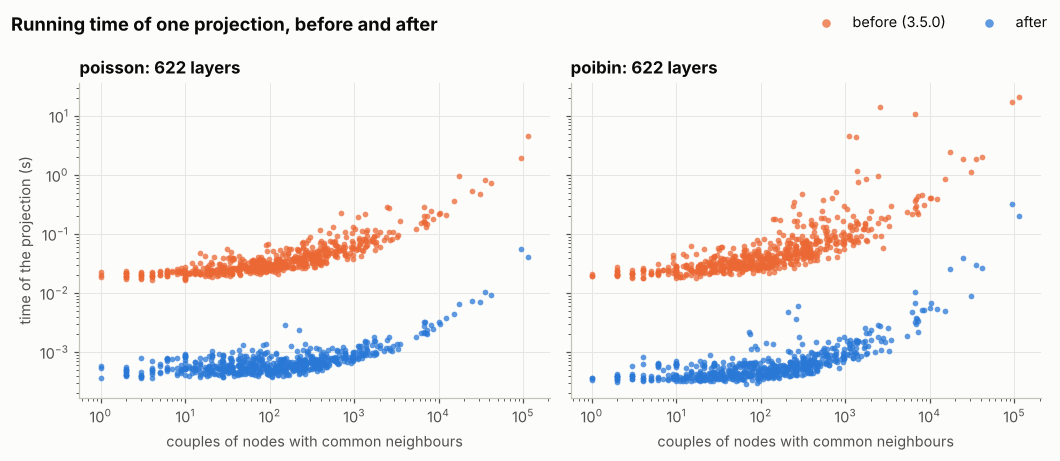

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.2), sharex=True, sharey=True)
for ax, method in zip(axes, ('poisson', 'poibin')):
    data = both[(both.method == method) & (both.pairs > 0)]
    ax.scatter(data.pairs, data.time_before, s=14, color=BEFORE, alpha=0.75, linewidths=0, label='before (3.5.0)')
    ax.scatter(data.pairs, data.time_after, s=14, color=AFTER, alpha=0.75, linewidths=0, label='after')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title('{}: {} layers'.format(method, len(data)))
    ax.set_xlabel('couples of nodes with common neighbours')
axes[0].set_ylabel('time of the projection (s)')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', ncol=2, markerscale=1.5)
fig.suptitle('Running time of one projection, before and after', x=0.01, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout()
plt.show()

## 5. The p-values

### An independent reference

To judge which version is right where they disagree, the exact p-value of every couple of nodes is computed here by brute force: the probability matrix of the BiCM gives the probability of each possible common neighbour, and the right tail of their sum is obtained with a plain dynamic programming over all the nodes of the opposite layer. This does not use the degree classes, the Fourier transforms or any other part of the projection code of either version.

In [8]:
@njit(parallel=True)
def brute_force_pvalues(probabilities, pairs_i, pairs_j, weights):
    out = np.empty(len(weights))
    for idx in prange(len(weights)):
        out[idx] = poibin_tail(probabilities[pairs_i[idx]] * probabilities[pairs_j[idx]], weights[idx])
    return out


import warnings

warnings.filterwarnings('ignore', category=bicm.BiCMWarning)  # square matrices, nodes with certain links

reference = {}
for name in solved:
    matrix = networks[name][0]
    graph = BipartiteGraph(biadjacency=matrix)
    graph.solve_tool(print_error=False)
    for layer in LAYERS:
        result = new[name]['projections'][(layer, 'poibin')]
        if 'pvals' not in result:
            continue
        probabilities = np.ascontiguousarray(graph.get_bicm_matrix() if layer == 'rows' else graph.get_bicm_matrix().T)
        biad = matrix if layer == 'rows' else matrix.T
        weights = (biad @ biad.T)[result['pairs_i'], result['pairs_j']]
        reference[(name, layer)] = brute_force_pvalues(probabilities, result['pairs_i'], result['pairs_j'],
                                                       weights.astype(np.int64))
print('{:,} couples of nodes in {} layers'.format(sum(len(p) for p in reference.values()), len(reference)))

673,246 couples of nodes in 628 layers


In [9]:
def collect(method):
    # All the couples where both versions and the reference have a p-value, in one table
    parts = []
    for (name, layer), ref in reference.items():
        before = old[name]['projections'].get((layer, method), {})
        after = new[name]['projections'].get((layer, method), {})
        if 'pvals' not in before or 'pvals' not in after:
            continue
        assert np.array_equal(before['pairs_i'], after['pairs_i']) and np.array_equal(before['pairs_j'], after['pairs_j'])
        parts.append(pd.DataFrame({'network': name, 'layer': layer, 'reference': ref,
                                   'before': before['pvals'], 'after': after['pvals']}))
    table = pd.concat(parts, ignore_index=True)
    table['full_nodes'] = table.network.map(nets.full_nodes) > 0
    return table


couples = {method: collect(method) for method in METHODS}
{method: '{:,} couples'.format(len(table)) for method, table in couples.items()}

{'poisson': '673,246 couples',
 'poibin': '673,246 couples',
 'normal': '673,246 couples',
 'rna': '673,246 couples'}

### Exact method (`poibin`)

Relative error of the two versions against the reference, by size of the p-value. The old version computed the tail as `1 - cdf` from a Fourier transform: it cannot resolve anything below about 1e-15, and it returns values that are null, negative or pure noise there.

In [10]:
def error_table(table, bins=(1e-300, 1e-15, 1e-10, 1e-5, 1e-2, 1.0000001)):
    rows = []
    for low, high in zip(bins[:-1], bins[1:]):
        part = table[(table.reference >= low) & (table.reference < high)]
        if len(part) == 0:
            continue
        with np.errstate(divide='ignore', invalid='ignore'):
            err_before = np.abs(part.before / part.reference - 1)
            err_after = np.abs(part.after / part.reference - 1)
        rows.append({'reference p-value': '{:.0e} to {:.0e}'.format(low, min(high, 1)), 'couples': len(part),
                     'median error before': err_before.median(), 'max error before': err_before.max(),
                     'median error after': err_after.median(), 'max error after': err_after.max(),
                     'before <= 0': int((part.before <= 0).sum())})
    return pd.DataFrame(rows).set_index('reference p-value')


exact = couples['poibin']
def show(table):
    table = table.copy()
    for column in table.columns:
        if 'error' in column:
            table[column] = table[column].map('{:.1e}'.format)
    display(table)


print('couples of networks without full nodes')
show(error_table(exact[~exact.full_nodes]))
print('couples of networks with nodes linked to the whole opposite layer')
show(error_table(exact[exact.full_nodes]))

couples of networks without full nodes


,couples,median error before,max error before,median error after,max error after,before <= 0
reference p-value,,,,,,
1e-300 to 1e-15,7,3.1e+03,8.4e+05,2.9e-15,1.1e-14,1
1e-15 to 1e-10,34,2.8e-04,1.2e+00,1.9e-15,6.4e-15,0
1e-10 to 1e-05,305,5.9e-09,2.5e-04,2.0e-15,1.8e-14,0
1e-05 to 1e-02,11403,3.6e-12,5.5e-09,1.7e-15,2.6e-14,0
1e-02 to 1e+00,653042,4.0e-15,5.3e-12,4.4e-16,3.1e-14,0


couples of networks with nodes linked to the whole opposite layer


,couples,median error before,max error before,median error after,max error after,before <= 0
reference p-value,,,,,,
1e-02 to 1e+00,8455,3.0e-01,1.0e+00,1.1e-16,3.3e-15,2866


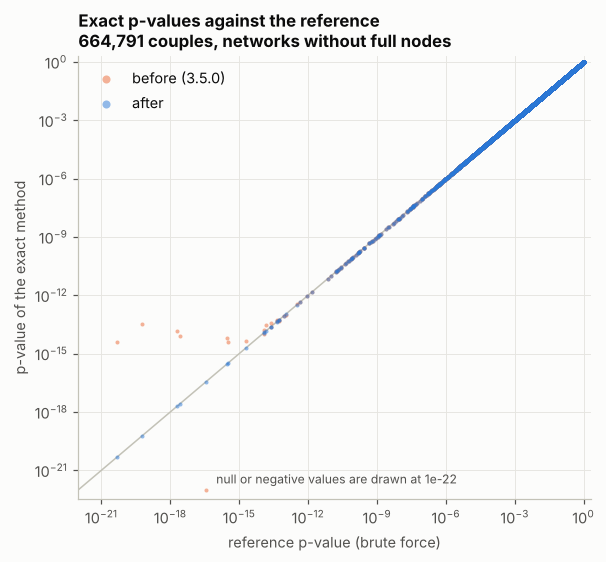

In [11]:
plain = exact[~exact.full_nodes & (exact.reference > 0)]
floor = 1e-22
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([floor, 1], [floor, 1], color='#c3c2b7', linewidth=1, zorder=1)
ax.scatter(plain.reference, np.clip(plain.before, floor, None), s=7, color=BEFORE, alpha=0.5, linewidths=0,
           label='before (3.5.0)', zorder=2)
ax.scatter(plain.reference, np.clip(plain.after, floor, None), s=7, color=AFTER, alpha=0.5, linewidths=0,
           label='after', zorder=3)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(floor, 2)
ax.set_ylim(floor / 3, 2)
ax.set_xlabel('reference p-value (brute force)')
ax.set_ylabel('p-value of the exact method')
ax.set_title('Exact p-values against the reference\n{:,} couples, networks without full nodes'.format(len(plain)))
ax.text(1e-16, floor * 1.5, 'null or negative values are drawn at {:.0e}'.format(floor), color=MUTED, fontsize=8, va='bottom')
ax.legend(loc='upper left', markerscale=2)
fig.tight_layout()
plt.show()

### Poisson approximation

The formula did not change: on networks without full nodes the two versions must agree to rounding. They differ on the networks with nodes linked to the whole opposite layer, where the old version gave those nodes a null fitness in the projection.

In [12]:
poisson = couples['poisson']
with np.errstate(divide='ignore', invalid='ignore'):
    poisson['difference'] = np.abs(poisson.before - poisson.after) / np.maximum(poisson.before, poisson.after)
poisson.loc[poisson.before == poisson.after, 'difference'] = 0.0
agreement = poisson.groupby('full_nodes').agg(
    networks=('network', 'nunique'), couples=('difference', 'size'), max_relative_difference=('difference', 'max'),
    couples_differing_more_than_1e_9=('difference', lambda d: int((d > 1e-9).sum())),
    null_pvalues_before=('before', lambda p: int((p == 0).sum())), null_pvalues_after=('after', lambda p: int((p == 0).sum())))
agreement.index = ['networks without full nodes', 'networks with full nodes']
agreement

,networks,couples,max_relative_difference,couples_differing_more_than_1e_9,null_pvalues_before,null_pvalues_after
networks without full nodes,281,664791,5.641771e-14,0,0,0
networks with full nodes,32,8455,1.000000e+00,4479,2866,0


### Normal and refined normal approximations

A sound approximation must rank the couples like the exact distribution. The table reports the rank correlation between the approximate and the reference p-values, over all the couples of each layer with at least 20 couples (median over the layers), and how many p-values at or below 0.05 of the reference each version also puts below 0.05.

In [13]:
def rank_correlation(a, b):
    ranks_a, ranks_b = pd.Series(a).rank().to_numpy(), pd.Series(b).rank().to_numpy()
    if ranks_a.std() == 0 or ranks_b.std() == 0:
        return np.nan
    return float(np.corrcoef(ranks_a, ranks_b)[0, 1])


rows = []
for method in ('poisson', 'normal', 'rna'):
    table = couples[method][~couples[method].full_nodes]
    groups = [g for _, g in table.groupby(['network', 'layer']) if len(g) >= 20]
    significant = table[table.reference <= 0.05]
    rows.append({'method': method, 'layers': len(groups),
                 'rank correlation before': np.nanmedian([rank_correlation(g.before, g.reference) for g in groups]),
                 'rank correlation after': np.nanmedian([rank_correlation(g.after, g.reference) for g in groups]),
                 'reference p <= 0.05': len(significant),
                 'of which before <= 0.05': int((significant.before <= 0.05).sum()),
                 'of which after <= 0.05': int((significant.after <= 0.05).sum())})
pd.DataFrame(rows).set_index('method').round(3)

,layers,rank correlation before,rank correlation after,reference p <= 0.05,of which before <= 0.05,of which after <= 0.05
method,,,,,,
poisson,473,0.998,0.998,52138,48232,48232
normal,473,-0.962,0.996,52138,0,52118
rna,473,-0.968,0.999,52138,0,29958


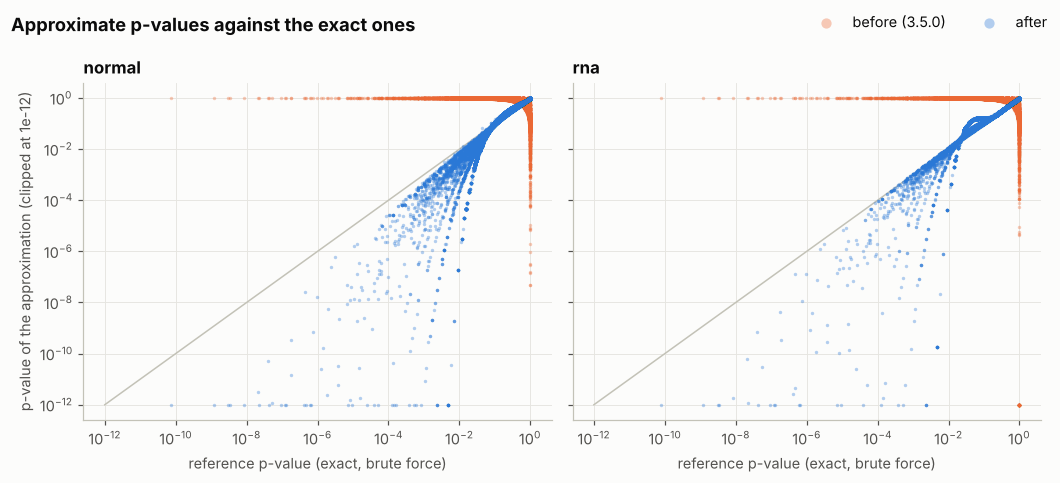

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.4), sharex=True, sharey=True)
floor = 1e-12
for ax, method in zip(axes, ('normal', 'rna')):
    table = couples[method][~couples[method].full_nodes]
    table = table[table.reference > floor]
    if len(table) > 60000:
        table = table.sample(60000, random_state=0)
    ax.plot([floor, 1], [floor, 1], color='#c3c2b7', linewidth=1, zorder=1)
    ax.scatter(table.reference, np.clip(table.before, floor, 1), s=5, color=BEFORE, alpha=0.35, linewidths=0,
               label='before (3.5.0)', zorder=2)
    ax.scatter(table.reference, np.clip(table.after, floor, 1), s=5, color=AFTER, alpha=0.35, linewidths=0,
               label='after', zorder=3)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(method)
    ax.set_xlabel('reference p-value (exact, brute force)')
axes[0].set_ylabel('p-value of the approximation (clipped at {:.0e})'.format(floor))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', ncol=2, markerscale=3)
fig.suptitle('Approximate p-values against the exact ones', x=0.01, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout()
plt.show()

## 6. The validated links

Number of links validated by each version with the FDR procedure at the significance level `ALPHA`, summed over all the layers where both versions ran, and number of layers where the two sets of links differ. The last columns compare each version with the links obtained from the reference p-values with the same procedure (exact method only: for the approximations the reference is not the target).

In [15]:
from bicm.validation import validate_pvalues


def link_set(result):
    return set(map(tuple, result['links']))


rows = []
for method in METHODS:
    for full in (False, True):
        totals = {'method': method, 'networks': 'with full nodes' if full else 'without full nodes', 'layers': 0,
                  'links before': 0, 'links after': 0, 'layers with different links': 0,
                  'wrong links before': 0, 'wrong links after': 0}
        for name in solved:
            if (nets.full_nodes[name] > 0) != full:
                continue
            for layer in LAYERS:
                before = old[name]['projections'].get((layer, method), {})
                after = new[name]['projections'].get((layer, method), {})
                if 'links' not in before or 'links' not in after:
                    continue
                links_before, links_after = link_set(before), link_set(after)
                totals['layers'] += 1
                totals['links before'] += len(links_before)
                totals['links after'] += len(links_after)
                totals['layers with different links'] += links_before != links_after
                if method == 'poibin' and (name, layer) in reference:
                    n_nodes = nets.rows[name] if layer == 'rows' else nets['columns'][name]
                    mask = validate_pvalues(reference[(name, layer)], alpha=ALPHA, method='fdr',
                                            n_tests=max(n_nodes * (n_nodes - 1) // 2, 1))[0]
                    truth = set(zip(after['pairs_i'][mask].tolist(), after['pairs_j'][mask].tolist()))
                    totals['wrong links before'] += len(links_before ^ truth)
                    totals['wrong links after'] += len(links_after ^ truth)
        if method != 'poibin':
            totals['wrong links before'] = totals['wrong links after'] = '-'
        rows.append(totals)
links = pd.DataFrame(rows).set_index(['method', 'networks'])
links

layers  links before  links after  \
method  networks                                                
poisson without full nodes     564           417          417   
        with full nodes         64          2885            0   
poibin  without full nodes     564          2621         2621   
        with full nodes         64          3009            0   
normal  without full nodes     564           435        10187   
        with full nodes         64             0            0   
rna     without full nodes     564           914         4389   
        with full nodes         64             0            0   

                            layers with different links wrong links before  \
method  networks                                                             
poisson without full nodes                            0                  -   
        with full nodes                              46                  -   
poibin  without full nodes                            0                  0   
        with full nodes                              47               3009   
normal  without full nodes                           39                  -   
        with full nodes                               0                  -   
rna     without full nodes                           32                  -   
        with full nodes                               0                  -   

                           wrong links after  
method  networks                              
poisson without full nodes                 -  
        with full nodes                    -  
poibin  without full nodes                 0  
        with full nodes                    0  
normal  without full nodes                 -  
        with full nodes                    -  
rna     without full nodes                 -  
        with full nodes                    -

In [16]:
changed = []
for name in solved:
    for layer in LAYERS:
        before = old[name]['projections'].get((layer, 'poisson'), {})
        after = new[name]['projections'].get((layer, 'poisson'), {})
        if 'links' in before and 'links' in after and link_set(before) != link_set(after):
            changed.append({'network': name, 'type': nets.type[name], 'layer': layer,
                            'shape': '{} x {}'.format(nets.rows[name], nets['columns'][name]),
                            'full nodes': nets.full_nodes[name],
                            'links before': len(before['links']), 'links after': len(after['links']),
                            'null p-values before': int((before['pvals'] == 0).sum())})
print('layers whose links change with the poisson method (the default of 3.5.0):', len(changed))
pd.DataFrame(changed).set_index(['network', 'layer']) if changed else None

layers whose links change with the poisson method (the default of 3.5.0): 46


type    shape  full nodes  links before  \
network     layer                                                         
M_AF_002_09 rows        Anemone-Fish    4 x 4           1             5   
            columns     Anemone-Fish    4 x 4           1             3   
M_SD_030    rows      Seed Dispersal    5 x 4           2             7   
            columns   Seed Dispersal    5 x 4           2             5   
M_PL_061_34 columns      Pollination    3 x 7           1             6   
M_PL_069_03 rows         Pollination    7 x 4           1            15   
            columns      Pollination    7 x 4           1             6   
M_SD_028    rows      Seed Dispersal    8 x 5           3            27   
            columns   Seed Dispersal    8 x 5           3            10   
A_HP_017    rows       Host-Parasite    5 x 9           2            10   
            columns    Host-Parasite    5 x 9           2            35   
M_SD_027    rows      Seed Dispersal   12 x 4           4            38   
            columns   Seed Dispersal   12 x 4           4             6   
M_PL_061_25 columns      Pollination   5 x 11           1            10   
M_PL_070    rows         Pollination    8 x 8           4            23   
            columns      Pollination    8 x 8           4            17   
A_HP_011    columns    Host-Parasite   4 x 19           3            51   
M_SD_032    columns   Seed Dispersal   4 x 19           2            35   
M_PL_061_12 rows         Pollination   7 x 12           1             6   
            columns      Pollination   7 x 12           1            11   
M_PL_061_02 columns      Pollination   5 x 17           1            16   
A_HP_005    rows       Host-Parasite   7 x 13           2            11   
            columns    Host-Parasite   7 x 13           2            12   
M_PL_061_30 columns      Pollination   7 x 13           1            12   
M_PL_061_31 columns      Pollination   5 x 19           2            35   
M_PL_061_08 columns      Pollination   6 x 19           1            18   
M_SD_015    columns   Seed Dispersal   5 x 27           4            98   
M_SD_001    columns   Seed Dispersal   7 x 21           1            20   
M_PL_067    rows         Pollination   31 x 5           2           140   
            columns      Pollination   31 x 5           2             7   
M_SD_008    rows      Seed Dispersal  16 x 10           2            15   
            columns   Seed Dispersal  16 x 10           2             9   
M_PL_059    rows         Pollination  13 x 13           2            12   
            columns      Pollination  13 x 13           2            23   
M_AF_001    rows        Anemone-Fish  10 x 26           1            17   
            columns     Anemone-Fish  10 x 26           1            25   
M_PL_061_06 columns      Pollination  11 x 24           1            23   
A_HP_026    columns    Host-Parasite  15 x 18           2            33   
M_SD_014    rows      Seed Dispersal  16 x 17           1            15   
M_SD_002    rows      Seed Dispersal   31 x 9           1            30   
M_PL_074_16 rows         Pollination  23 x 13           1            22   
A_PH_007    rows     Plant-Herbivore   5 x 64           1             4   
            columns  Plant-Herbivore   5 x 64           1          1845   
M_SD_010    rows      Seed Dispersal  50 x 14           1            49   
A_HP_044    columns    Host-Parasite  27 x 26           1            25   
M_PL_046    columns      Pollination  16 x 44           1            43   

                     links after  null p-values before  
network     layer                                       
M_AF_002_09 rows               0                     5  
            columns            0                     3  
M_SD_030    rows               0                     7  
            columns            0                     5  
M_PL_061_34 columns            0                     6  
M_PL_069_03 rows               0

## 7. The weighted models

213 networks of the database have weights different from one: 195 with integer weights (counts of interactions) and 18 with real weights (mostly food webs, with weights much smaller than one). The worker solves on each of them:

* the **BiWCM_d**, the discrete model, on the networks with integer weights;
* the **BiWCM_c**, the continuous model, on all of them (integer weights are a particular case of real weights).

Then it computes the p-value of every link (the probability that the model gives the link a weight at least as large as the observed one) and validates the links at the significance level 0.01 with the three procedures.

The solver is judged by the largest relative error of the expected strengths, computed from the expected matrix that each version returns. The p-values are compared with the survival functions of scipy: geometric for the discrete model, exponential for the continuous one.

In [17]:
ALPHA_WEIGHTED = 0.01
new_w = run_worker('new_weighted', '--weighted', '--alpha', str(ALPHA_WEIGHTED), '--timeout', str(TIMEOUT))
old_w = run_worker('old_weighted', '--weighted', '--alpha', str(ALPHA_WEIGHTED), '--timeout', str(TIMEOUT),
                   '--bicm-path', str(OLD))
old_w.pop('__version__'), new_w.pop('__version__')
weighted = wol_worker.load_weighted_networks(DATA / 'networks.json')
MODELS = ('biwcm_d', 'biwcm_c')
CONVERGED = 1e-5   # relative error of the expected strengths


def outcome(record):
    if 'error' in record:
        return 'error'
    if 'skipped' in record:
        return record['skipped']
    return 'converged' if record['strength_error'] < CONVERGED else 'not converged'


wruns = pd.DataFrame([{'network': name, 'model': model, 'cells': weighted[name].size,
                       'smallest_weight': weighted[name][weighted[name] > 0].min(),
                       'before': outcome(old_w[(name, model)]), 'after': outcome(new_w[(name, model)]),
                       'error_before': old_w[(name, model)].get('strength_error', np.nan),
                       'error_after': new_w[(name, model)].get('strength_error', np.nan),
                       'time_before': old_w[(name, model)].get('solve_time', np.nan),
                       'time_after': new_w[(name, model)].get('solve_time', np.nan)}
                      for (name, model) in new_w])
outcomes = pd.concat({'before': wruns.groupby('model')['before'].value_counts().unstack(fill_value=0),
                      'after': wruns.groupby('model')['after'].value_counts().unstack(fill_value=0)}, axis=1).fillna(0).astype(int)
display(outcomes.loc[list(MODELS)])
print('errors before:', pd.Series([old_w[key]['error'] for key in old_w if 'error' in old_w[key]]).value_counts().to_dict())
display(wruns.groupby('model').agg(solve_time_before_s=('time_before', 'sum'), solve_time_after_s=('time_after', 'sum'),
                                   worst_error_before=('error_before', 'max'), worst_error_after=('error_after', 'max'))
        .loc[list(MODELS)])
failed = wruns[(wruns.model == 'biwcm_c') & (wruns.before != 'converged')]
print('BiWCM_c, networks not converged before: {}; their smallest weights are between {:.0e} and {:.0e}'.format(
    len(failed), failed.smallest_weight.min(), failed.smallest_weight.max()))

before                         after
        converged error not converged converged
model                                          
biwcm_d       187     8             0       195
biwcm_c       198     0            15       213

errors before: {"LinAlgError('Singular matrix')": 8}


,solve_time_before_s,solve_time_after_s,worst_error_before,worst_error_after
model,,,,
biwcm_d,2.562706,3.087171,0.000004,4.278708e-06
biwcm_c,29.227384,1.250763,1.000000,2.886580e-15


BiWCM_c, networks not converged before: 15; their smallest weights are between 1e-06 and 1e+00


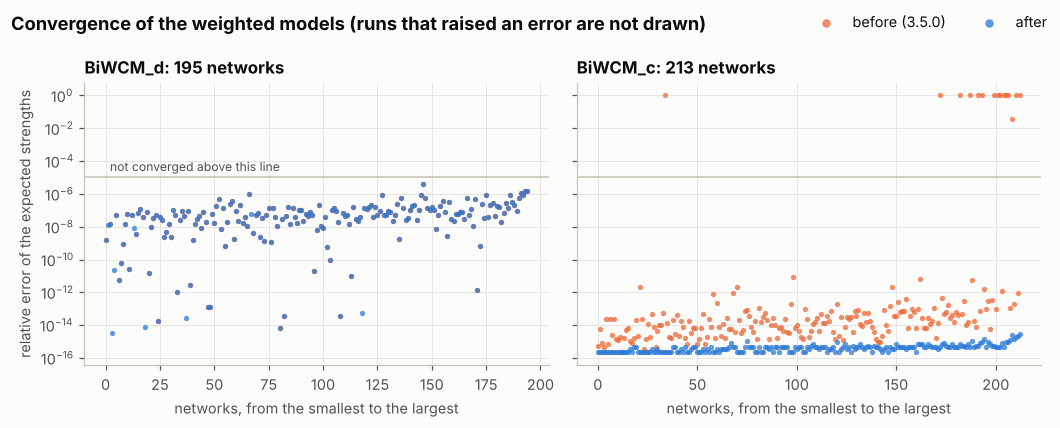

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.9), sharey=True)
floor = 1e-17
for ax, model in zip(axes, MODELS):
    data = wruns[wruns.model == model].sort_values('cells').reset_index(drop=True)
    for column, colour, label in (('error_before', BEFORE, 'before (3.5.0)'), ('error_after', AFTER, 'after')):
        solved_runs = data[column].notna()
        ax.scatter(data.index[solved_runs], np.clip(data[column][solved_runs], floor, None), s=12, color=colour,
                   alpha=0.75, linewidths=0, label=label)
    ax.axhline(CONVERGED, color='#c3c2b7', linewidth=1)
    ax.set_yscale('log')
    ax.set_title('{}: {} networks'.format(model.replace('biwcm', 'BiWCM'), len(data)))
    ax.set_xlabel('networks, from the smallest to the largest')
axes[0].set_ylabel('relative error of the expected strengths')
axes[0].text(2, CONVERGED * 2.5, 'not converged above this line', color=MUTED, fontsize=8)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', ncol=2, markerscale=1.6)
fig.suptitle('Convergence of the weighted models (runs that raised an error are not drawn)', x=0.01, ha='left',
             fontsize=12, fontweight='bold')
fig.tight_layout()
plt.show()

### Solution and p-values where both versions converge

Where the old version converged the two versions must give the same model. The p-values of the links are compared with scipy, using the parameters of the new version.

In [19]:
from scipy import stats

rows = []
for model in MODELS:
    keys = [(name, m) for (name, m) in new_w if m == model
            and outcome(old_w[(name, m)]) == 'converged' and outcome(new_w[(name, m)]) == 'converged']
    theta_diff, err_before, err_after, n_links, bad_before, bad_after = [], [], [], 0, 0, 0
    for key in keys:
        before, after, matrix = old_w[key], new_w[key], weighted[key[0]]
        rates = after['theta_x'][:, None] + after['theta_y'][None, :]
        theta_diff.append(max(relative_difference(before['theta_x'], after['theta_x']),
                              relative_difference(before['theta_y'], after['theta_y'])))
        if model == 'biwcm_d':
            target = stats.geom.sf(matrix, -np.expm1(-rates))     # P(w >= k) = exp(-rate * k)
        else:
            target = stats.expon.sf(matrix * rates)
        links_mask = (matrix > 0) & (target > 1e-300)
        n_links += int(links_mask.sum())
        with np.errstate(divide='ignore', invalid='ignore'):
            err_before.append(np.abs(before['pvals'][links_mask] / target[links_mask] - 1).max())
            err_after.append(np.abs(after['pvals'][links_mask] / target[links_mask] - 1).max())
        for pvals, counter in ((before['pvals'], 'before'), (after['pvals'], 'after')):
            wrong = int((np.isnan(pvals) | (pvals > 1) | (pvals < 0) | ((matrix == 0) & (pvals != 1))).sum())
            bad_before, bad_after = (bad_before + wrong, bad_after) if counter == 'before' else (bad_before, bad_after + wrong)
    rows.append({'model': model, 'networks': len(keys), 'largest difference of theta': max(theta_diff),
                 'links': n_links, 'p-values: max error before': max(err_before), 'p-values: max error after': max(err_after),
                 'invalid p-values before': bad_before, 'invalid p-values after': bad_after})
pd.DataFrame(rows).set_index('model')

,networks,largest difference of theta,links,p-values: max error before,p-values: max error after,invalid p-values before,invalid p-values after
model,,,,,,,
biwcm_d,187,0.000000e+00,19492,2.185940e-11,2.185940e-11,0,0
biwcm_c,198,5.806579e-11,17856,1.954326e-11,0.000000e+00,0,0


### Validated links

Number of links validated by each version, on the networks where both converged. With the global threshold the two versions agree. With FDR and Bonferroni the old version counted as tests the couples of columns, `n_cols * (n_cols - 1) / 2`, instead of the entries of the matrix, `n_rows * n_cols`: its threshold was too loose or too strict depending on the shape of the matrix.

In [20]:
rows = []
for model in MODELS:
    for method in ('global', 'fdr', 'bonferroni'):
        totals = {'model': model, 'validation': method, 'networks': 0, 'links': 0, 'validated before': 0,
                  'validated after': 0, 'networks with different links': 0}
        for (name, m) in new_w:
            if m != model or outcome(old_w[(name, m)]) != 'converged' or outcome(new_w[(name, m)]) != 'converged':
                continue
            before, after = old_w[(name, m)]['validated'][method], new_w[(name, m)]['validated'][method]
            totals['networks'] += 1
            totals['links'] += int((weighted[name] > 0).sum())
            totals['validated before'] += int(before.sum())
            totals['validated after'] += int(after.sum())
            totals['networks with different links'] += int(not np.array_equal(before, after))
        rows.append(totals)
pd.DataFrame(rows).set_index(['model', 'validation'])

networks  links  validated before  validated after  \
model   validation                                                       
biwcm_d global           187  19492              2765             2765   
        fdr              187  19492               395              344   
        bonferroni       187  19492               244              225   
biwcm_c global           198  17856              7139             7139   
        fdr              198  17856              5077             4783   
        bonferroni       198  17856              3472             3409   

                    networks with different links  
model   validation                                 
biwcm_d global                                  0  
        fdr                                    39  
        bonferroni                             32  
biwcm_c global                                  0  
        fdr                                    84  
        bonferroni                             72

### Cross-check with the PyTorch implementation

`bicm.wbnm.BiWCM` is an independent implementation of the continuous model (from the `wbnm` package, with a different solver). Where both converge the expected matrices must coincide. This cell is skipped if PyTorch is not installed.

In [21]:
try:
    from bicm.wbnm import BiWCM
except ImportError:
    BiWCM = None
    print('PyTorch is not installed: cross-check skipped')

if BiWCM is not None:
    rows = []
    for name, matrix in weighted.items():
        model = BiWCM(matrix).solve()
        expected = model.expected_matrix().numpy()
        torch_error = max(np.abs(expected.sum(1) / matrix.sum(1) - 1).max(), np.abs(expected.sum(0) / matrix.sum(0) - 1).max())
        after = new_w[(name, 'biwcm_c')]
        ours = 1 / (after['theta_x'][:, None] + after['theta_y'][None, :])
        rows.append({'network': name, 'torch_error': torch_error, 'after': outcome(after),
                     'before': outcome(old_w[(name, 'biwcm_c')]), 'disagreement': np.abs(expected / ours - 1).max()})
    cross = pd.DataFrame(rows)
    both_ok = (cross.torch_error < CONVERGED) & (cross.after == 'converged')
    print('networks: {}, converged with bicm.wbnm: {}, with BipartiteGraph after: {}, before: {}'.format(
        len(cross), int((cross.torch_error < CONVERGED).sum()), int((cross.after == 'converged').sum()),
        int((cross.before == 'converged').sum())))
    print('largest relative difference between the expected matrices of the two implementations: {:.1e}'.format(
        cross.disagreement[both_ok].max()))

networks: 213, converged with bicm.wbnm: 213, with BipartiteGraph after: 213, before: 198
largest relative difference between the expected matrices of the two implementations: 3.3e-08


## 8. Summary

The cell below collects the numbers of this run. The interpretation follows.

In [22]:
exact_plain = exact[~exact.full_nodes]
tiny = exact_plain[(exact_plain.reference > 0) & (exact_plain.reference < 1e-15)]
with np.errstate(divide='ignore', invalid='ignore'):
    worst_after = np.abs(exact_plain.after[exact_plain.reference > 0] / exact_plain.reference[exact_plain.reference > 0] - 1).max()
print('networks: {} ({} with nodes linked to the whole opposite layer)'.format(len(nets), int((nets.full_nodes > 0).sum())))
print('solver: largest relative difference of the fitnesses {:.1e}'.format(nets.fitness_diff.max()))
for method in METHODS:
    print('{:8s} total time before {:8.1f} s, after {:6.2f} s, {:6.0f} times faster on {} layers'.format(
        method, speed.total_before_s[method], speed.total_after_s[method], speed.total_speedup[method], speed.layers[method]))
print('exact method, largest relative error after, against the reference: {:.1e}'.format(worst_after))
print('exact method, couples with reference p-value below 1e-15: {}, of which the old version returned <= 0 for {}'.format(
    len(tiny), int((tiny.before <= 0).sum())))

networks: 318 (36 with nodes linked to the whole opposite layer)
solver: largest relative difference of the fitnesses 0.0e+00
poisson  total time before     37.3 s, after   0.59 s,     63 times faster on 628 layers
poibin   total time before    124.7 s, after   1.12 s,    111 times faster on 628 layers
normal   total time before     51.0 s, after   0.54 s,     95 times faster on 628 layers
rna      total time before     61.6 s, after   0.60 s,    103 times faster on 628 layers
exact method, largest relative error after, against the reference: 3.1e-14
exact method, couples with reference p-value below 1e-15: 7, of which the old version returned <= 0 for 1


### Reading of the results: binary networks

The numbers below are those of the run stored in this notebook (318 networks, 673,246 couples of nodes, 4 cores). The times change with the machine, the rest does not.

**Same model, same answers where the old version was right.** The fitnesses are identical. On the 281 networks without nodes linked to the whole opposite layer, the Poisson p-values agree within 6e-14 and the validated links of the `poisson` and `poibin` methods are the same in all the 564 layers.

**Speed.** Every method is about 65 to 110 times faster over the whole database (for instance the exact method goes from 125 s to 1.2 s), and more than 4 times faster on every single layer. The old version pays about 20 ms for each projection to start its processes, the new one starts at about 0.5 ms; the gap grows again on the largest networks.

**Exact p-values.** The new exact method agrees with the brute force reference within 3e-14 in relative terms for every couple, however small the p-value. The old one loses digits progressively below 1e-5 and is wrong by orders of magnitude below 1e-15 (in one case it returned a null or negative value). With these small networks only a handful of couples are that significant; on larger networks they are the ones that matter most.

**Nodes linked to the whole opposite layer.** 36 networks have such nodes. In 32 of them the old version gave p-value zero to 2,866 couples, which were all validated: about 2,900 links with `poisson` and 3,000 with `poibin`, none of which is validated with the reference p-values. The new version agrees with the reference within 4e-15. The other four networks are perfectly nested: the old version failed on them, the new one returns p-values equal to one.

**Normal and refined normal approximations.** In the old version their rank correlation with the exact p-values was -0.96 and -0.97: they were the opposite tail, and none of the 52,138 couples with exact p-value below 0.05 was below 0.05. They are now the right tail (rank correlation above 0.99). Note however that on networks as small and sparse as these they are poor approximations: they underestimate the small p-values (points below the diagonal in the last chart) and the normal method validates about four times the links of the exact one. The Poisson approximation is conservative instead (417 links against 2,621). Since the exact method now costs about the same, it is the one to prefer.

### Reading of the results: weighted models

On the weighted networks the benchmark found three problems of the solver itself, present in both versions when it was first run, which are now fixed in the package:

**BiWCM_d: singular Hessian.** On 8 small networks out of 195 the Newton step met a singular matrix and the solver stopped with an error. The step now falls back to its least squares solution, and all the 195 networks converge.

**BiWCM_c: underflow of the fitnesses.** The expected matrix and the p-values were computed from the fitnesses `x = exp(-theta)`, which are zero when `theta` is larger than about 745, that is when the weights are much smaller than one. The solver had found the right `theta`, but the expected weights came out null and the p-values wrong. They are now computed from `theta`.

**BiWCM_c: line search of the fixed-point solver.** On some networks the line search shrank the step until the solver stalled far from the solution. It is now off by default for this solver, which converges on all the 213 networks (15 did not before) and is about 20 times faster in total.

Where the old version converged the two versions give the same parameters and the same p-values, both within 1e-10 of scipy. The links validated with the global threshold are identical; those validated with FDR and Bonferroni change because of the number of tests, as explained above. The independent PyTorch implementation of the continuous model converges on all the networks and agrees with the new version.